# TP05: a vision project, then activations and initialisation

**MSA-DATB09-03 · Neural Networks & Deep Learning Foundations · Session 5 / 8** · Guillaume Saint-Cirgue

*Estimated time: 100 minutes (Part A: 40 minutes before the second part of the course, Parts B to D: 60 minutes)*

You now master the PyTorch pipeline of Session 4. Today you use it on a real computer-vision problem:
recognising clothes in 28x28 photos (FashionMNIST). In Part A you build and train the network of Sessions 3
and 4 yourself. Then we try to make it deeper, and it breaks: Part B measures why (the vanishing gradient),
Part C fixes it with ReLU and compares the other activations, and Part D shows how the initial weights decide
whether a deep network can learn at all (Xavier and He initialisation).

**How it works.** Each exercise is a cell with a zone to complete:

```python
### START CODE HERE ###

### END CODE HERE ###
```

Write your code between the two markers, then run the cell: the `assert` lines below the zone check your
answer and print `Exercise validated!` when it is correct. If an assert fails, read its message: it tells
you what to look at.

**Run it** on Google Colab (File > Upload notebook) or locally with the course `requirements.txt`. A GPU is
not needed: the whole notebook trains in about 3 minutes on a laptop CPU.

## Imports

- `torch`, `torch.nn`, `torch.utils.data`: PyTorch, as in Session 4.
- `torchvision.datasets`: ready-made datasets; `FashionMNIST` downloads the images (about 30 MB) the first
  time into `DATA_DIR`.
- `sklearn.metrics.confusion_matrix`: counts, for each true class, how often each class was predicted.
- `numpy`, `matplotlib`: arrays and plots.

`FAST_RUN = True` (environment variable `FAST_RUN=1`) uses 30 000 training images and fewer epochs, for a
quick check. Leave it `False` in class.

In [1]:
import os
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from torchvision import datasets
from sklearn.metrics import confusion_matrix

FAST_RUN = os.environ.get("FAST_RUN", "0") == "1"   # True: smaller data and fewer epochs for a quick check
DATA_DIR = os.environ.get("DATA_DIR", "./data")
np.random.seed(0)
torch.manual_seed(0)
torch.set_num_threads(2)
device = "cuda" if torch.cuda.is_available() else "cpu"

N_TRAIN = 30_000 if FAST_RUN else 50_000    # training images used
EPOCHS_A = 4 if FAST_RUN else 10            # epochs for the Part A baseline
EPOCHS = 3 if FAST_RUN else 5               # epochs for each experiment of Parts B to D
BATCH_SIZE = 128
LR = 0.2                                    # SGD learning rate of Parts A to C
CLASSES = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
           "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]
print("device:", device, "| FAST_RUN:", FAST_RUN)

device: cpu | FAST_RUN: False


## Helper functions (run this cell, no need to modify it)

`evaluate`, `train_one_epoch` and `fit` are exactly the functions you wrote in TP04 (Exercises 20 and 24).
`fit` returns a dictionary with one value per epoch for `"train_loss"`, `"val_loss"` and `"val_acc"`.
`show_images` displays a few images with their labels.

In [2]:
def evaluate(model, loader, loss_fn):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            total_loss += loss_fn(logits, yb).item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            total += len(yb)
    return total_loss / total, correct / total


def train_one_epoch(model, loader, loss_fn, optimizer):
    model.train()
    running, total = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        logits = model(xb)
        loss = loss_fn(logits, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        running += loss.item() * len(yb)
        total += len(yb)
    return running / total


def fit(model, train_loader, val_loader, loss_fn, optimizer, n_epochs, verbose=True):
    history = {"train_loss": [], "val_loss": [], "val_acc": []}
    for epoch in range(n_epochs):
        train_loss = train_one_epoch(model, train_loader, loss_fn, optimizer)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn)
        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        if verbose:
            print(f"epoch {epoch + 1:2d} | train loss {train_loss:.4f} | val loss {val_loss:.4f} | val acc {val_acc:.3f}")
    return history


def show_images(images, titles, n=10):
    fig, axes = plt.subplots(1, n, figsize=(1.5 * n, 1.9))
    for ax, img, title in zip(axes, images[:n], titles[:n]):
        ax.imshow(img.reshape(28, 28).cpu(), cmap="gray_r")
        ax.set_title(title, fontsize=8)
        ax.axis("off")
    plt.show()

# Part A: the project, classify clothes with your network

### Exercise 1: load FashionMNIST

`datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)` downloads (once) and opens the 60 000
training images; `train=False` gives the 10 000 test images. We do not need the image-by-image interface:
the attribute `.data` holds all the pixels in one `uint8` tensor of shape `(N, 28, 28)` (values 0 to 255)
and `.targets` the labels, an `int64` tensor of shape `(N,)`.

Create `X_full` (the training pixels converted to float32 and divided by 255, so in $[0, 1]$), `y_full`
(the training labels), and the same for the test set: `X_test_raw`, `y_test`.

> Hint: `train_set.data.float() / 255`.

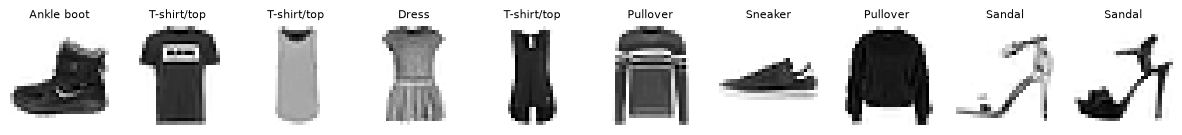

Exercise validated!


In [6]:
train_set = datasets.FashionMNIST(root=DATA_DIR, train=True, download=True)
test_set = datasets.FashionMNIST(root=DATA_DIR, train=False, download=True)
### START CODE HERE ###
X_full = train_set.data.float() / 255
y_full = train_set.targets

X_test_raw = test_set.data.float() / 255
y_test = test_set.targets
### END CODE HERE ###

assert X_full.shape == (60000, 28, 28) and X_full.dtype == torch.float32, "X_full: float32, shape (60000, 28, 28)"
assert X_full.max().item() == 1.0 and X_full.min().item() == 0.0, "divide the pixels by 255"
assert y_full.shape == (60000,) and y_full.dtype == torch.int64, "y_full: int64 labels"
assert X_test_raw.shape == (10000, 28, 28) and y_test.shape == (10000,), "test set: 10 000 images"
show_images(X_full, [CLASSES[k] for k in y_full[:10]])
print("Exercise validated!")

### Exercise 2: split and standardise

We keep the official test set for the very end, and split the 60 000 training images into a training part
(the first `N_TRAIN` indices of a random permutation) and a validation part (the last 10 000 indices).

Then we **standardise** the pixels: subtract the mean and divide by the standard deviation, so that the
inputs have mean 0 and standard deviation 1. This matters for deep networks (Part D assumes inputs of
variance 1). The mean and the standard deviation are computed **on the training part only** (two numbers
over all its pixels) and applied to the three sets: the validation and test sets must stay "unseen".

Complete: `mean`, `std` (Python floats, use `.item()`), then `X_train`, `X_val`, `X_test`.

In [7]:
perm = torch.randperm(60000, generator=torch.Generator().manual_seed(0))
train_idx, val_idx = perm[:N_TRAIN], perm[50000:]
X_train_raw, y_train = X_full[train_idx], y_full[train_idx]
X_val_raw, y_val = X_full[val_idx], y_full[val_idx]
### START CODE HERE ###

mean = X_train_raw.mean().item()
std = X_train_raw.std().item()

X_train = (X_train_raw - mean) / std
X_val = (X_val_raw - mean) / std
X_test = (X_test_raw - mean) / std

### END CODE HERE ###

print(f"mean {mean:.4f}, std {std:.4f} | train {len(X_train)}, val {len(X_val)}, test {len(X_test)}")
assert abs(mean - X_train_raw.mean().item()) < 1e-6, "mean of the TRAINING part only"
assert abs(X_train.mean().item()) < 1e-3 and abs(X_train.std().item() - 1) < 1e-3, "X_train should have mean 0 and std 1"
assert abs(X_test.mean().item() - (X_test_raw.mean().item() - mean) / std) < 1e-4, "standardise the test set with the TRAINING mean and std"
print("Exercise validated!")

mean 0.2865, std 0.3532 | train 50000, val 10000, test 10000
Exercise validated!


### Exercise 3: the DataLoaders

As in TP04, but with the ready-made `TensorDataset(X, y)` (it does what your `DigitsDataset` did): create
`train_loader` (batch size `BATCH_SIZE`, shuffled), `val_loader` and `test_loader` (batch size 1000, not
shuffled).

In [8]:
torch.manual_seed(0)
### START CODE HERE ###

train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val, y_val), batch_size=1000, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test, y_test), batch_size=1000, shuffle=False)

### END CODE HERE ###

xb, yb = next(iter(train_loader))
print("one batch:", tuple(xb.shape), tuple(yb.shape), "| batches per epoch:", len(train_loader))
assert xb.shape == (BATCH_SIZE, 28, 28) and yb.shape == (BATCH_SIZE,), "a batch: (128, 28, 28) images, (128,) labels"
assert isinstance(train_loader.sampler, torch.utils.data.RandomSampler), "shuffle the training loader"
assert len(val_loader.dataset) == 10000 and len(test_loader.dataset) == 10000, "validation and test: 10 000 images each"
print("Exercise validated!")

one batch: (128, 28, 28) (128,) | batches per epoch: 391
Exercise validated!


### Exercise 4: the 784-128-10 sigmoid network

A dense network takes a vector, not a 28x28 grid: `nn.Flatten()` reshapes each image of the batch from
`(28, 28)` to `(784,)` (a batch `(B, 28, 28)` becomes `(B, 784)`). It has no parameters.

`nn.Sequential(layer1, layer2, ...)` chains modules: the output of one is the input of the next. Build
`model` = flatten, a hidden layer of 128 sigmoid neurons (`nn.Linear` then `nn.Sigmoid()`), and an output
layer of 10 logits. It is the network of Session 4 on bigger images. How many parameters? By hand:
$784 \times 128 + 128 + 128 \times 10 + 10$. Store that number in `n_params` (computed with `numel`).

In [10]:
torch.manual_seed(0)
### START CODE HERE ###

model = nn.Sequential(
    nn.Flatten(),
    nn.Linear(784, 128),
    nn.Sigmoid(),
    nn.Linear(128, 10)
).to(device)

n_params = sum(p.numel() for p in model.parameters())

### END CODE HERE ###

print(model)
assert model(xb.to(device)).shape == (BATCH_SIZE, 10), "the model must map (B, 28, 28) to (B, 10) logits"
assert n_params == 784 * 128 + 128 + 128 * 10 + 10, f"expected 101770 parameters, got {n_params}"
assert any(isinstance(m, nn.Sigmoid) for m in model), "use a sigmoid hidden layer (the network of Session 4)"
print("Exercise validated!")

Sequential(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=128, bias=True)
  (2): Sigmoid()
  (3): Linear(in_features=128, out_features=10, bias=True)
)
Exercise validated!


### Exercise 5: train it

Create the loss (`nn.CrossEntropyLoss()`), the optimiser (`torch.optim.SGD` with `lr=LR`), and train for
`EPOCHS_A` epochs with `fit`. Store the returned dictionary in `history_a`.

In [ ]:
torch.manual_seed(0)
### START CODE HERE ###

loss = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(params=model.parameters(), lr=LR)
history_a = fit(model=model,
                train_loader=train_loader,
                val_loader=val_loader,
                loss_fn=loss,
                optimizer=optimizer,
                n_epochs=EPOCHS_A)

### END CODE HERE ###

assert len(history_a["val_acc"]) == EPOCHS_A, "train for EPOCHS_A epochs"
assert history_a["train_loss"][-1] < history_a["train_loss"][0], "the training loss should decrease"
assert history_a["val_acc"][-1] > 0.8, f"validation accuracy should exceed 0.8, got {history_a['val_acc'][-1]:.3f}"
print("Exercise validated!")

epoch  1 | train loss 0.3557 | val loss 0.3731 | val acc 0.865
epoch  2 | train loss 0.3422 | val loss 0.3883 | val acc 0.857
epoch  3 | train loss 0.3313 | val loss 0.3705 | val acc 0.863
epoch  4 | train loss 0.3208 | val loss 0.3566 | val acc 0.871
epoch  5 | train loss 0.3115 | val loss 0.3596 | val acc 0.869
epoch  6 | train loss 0.3043 | val loss 0.3385 | val acc 0.879
epoch  7 | train loss 0.2961 | val loss 0.3463 | val acc 0.874
epoch  8 | train loss 0.2893 | val loss 0.3423 | val acc 0.878
epoch  9 | train loss 0.2823 | val loss 0.3843 | val acc 0.863
epoch 10 | train loss 0.2758 | val loss 0.3469 | val acc 0.873
Exercise validated!


### Exercise 6: the test accuracy

Your baseline is chosen. Measure it once on the test set: `test_loss, test_acc` with `evaluate`.

In [16]:
### START CODE HERE ###

test_loss, test_acc = evaluate(model=model, loader=test_loader, loss_fn=loss)

### END CODE HERE ###

print(f"test accuracy of the baseline: {test_acc:.3f}")
assert test_acc > 0.8, f"the baseline should exceed 0.8 on the test set, got {test_acc:.3f}"
print("Exercise validated!")

test accuracy of the baseline: 0.864
Exercise validated!


### Exercise 7: the confusion matrix

The accuracy is one number; the confusion matrix tells **which** classes are mixed up. Entry `[i, j]` counts
the test images of true class `i` predicted as class `j`: the diagonal holds the correct predictions.

1. compute `pred`, the predicted class of every test image (one forward pass on `X_test` inside
   `torch.no_grad()`, then `argmax(dim=1)`; put the model in `eval()` mode first);
2. `cm = confusion_matrix(y_test.numpy(), pred.cpu().numpy())` (scikit-learn, a NumPy array `(10, 10)`);
3. find the most frequent mistake: `true_cls, pred_cls`, the indices `(i, j)` with `i != j` of the largest
   entry outside the diagonal.

> Hint: copy the matrix, set its diagonal to 0 with `np.fill_diagonal(off, 0)`, then
> `np.unravel_index(off.argmax(), off.shape)` turns the flat index of the maximum into `(row, column)`.

In [ ]:
### START CODE HERE ###

### END CODE HERE ###

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(10), CLASSES, rotation=90); plt.yticks(range(10), CLASSES)
plt.xlabel("predicted"); plt.ylabel("true"); plt.colorbar(); plt.show()
print(f"most frequent mistake: {CLASSES[true_cls]} predicted as {CLASSES[pred_cls]} ({cm[true_cls, pred_cls]} times)")
assert cm.shape == (10, 10) and cm.sum() == 10000, "the matrix counts the 10 000 test images"
assert abs(np.trace(cm) / cm.sum() - test_acc) < 1e-6, "the diagonal should match the test accuracy"
assert true_cls != pred_cls and cm[true_cls, pred_cls] == off.max(), "find the largest entry outside the diagonal"
print("Exercise validated!")

### Exercise 8: look at the mistakes

Store in `wrong` the indices of the misclassified test images (a 1-D tensor). `(pred != y_test)` is a
boolean tensor; `torch.nonzero(mask).flatten()` (or `torch.where(mask)[0]`) gives the indices of the
`True` entries. The helper then shows the first ten with "true / predicted".

In [ ]:
### START CODE HERE ###

### END CODE HERE ###

assert wrong.ndim == 1, "wrong must be a 1-D tensor of indices"
assert len(wrong) == int((1 - test_acc) * 10000 + 0.5), "one index per misclassified test image"
show_images(X_test_raw[wrong], [f"{CLASSES[y_test[i]]}\n/ {CLASSES[pred[i]]}" for i in wrong[:10]])
print("Exercise validated!")

**What we see.** About 85 % of the test images are correct with a single hidden layer. Most mistakes are
between visually close classes: shirt, T-shirt, pullover and coat (the upper-body clothes), and some
sandals, sneakers and ankle boots. Natural idea to do better: **make the network deeper**. That is the next
part, and it will not go as planned. Stop here and come back to the course.

# Part B: a deeper sigmoid network

### Exercise 9: a network of any depth

Write `make_mlp(depth, activation, width=128)` that returns an `nn.Sequential`: `nn.Flatten()`, then
`depth` hidden blocks `nn.Linear(n_in, width)` followed by `activation()`, then `nn.Linear(width, 10)`.
The first hidden layer has `n_in = 784`, the next ones `n_in = width`.

`activation` is a **class** (for example `nn.Sigmoid`), so `activation()` creates a new layer of that
type. Build the list of layers in a Python list `layers`, then `nn.Sequential(*layers)` (the star unpacks
the list into arguments).

In [ ]:
def make_mlp(depth, activation, width=128):
    ### START CODE HERE ###
    layers = []
    ### END CODE HERE ###
    return nn.Sequential(*layers)


deep = make_mlp(6, nn.Sigmoid)
linears = [m for m in deep if isinstance(m, nn.Linear)]
print(deep)
assert len(linears) == 7, f"6 hidden layers + 1 output layer = 7 nn.Linear, got {len(linears)}"
assert sum(isinstance(m, nn.Sigmoid) for m in deep) == 6, "one activation after each hidden layer, none after the output"
assert linears[0].in_features == 784 and linears[-1].out_features == 10, "784 inputs, 10 logits"
assert deep(xb).shape == (BATCH_SIZE, 10), "the output must be (B, 10)"
print("Exercise validated!")

### Exercise 10: the maximum of $\sigma'$, with autograd

In the course we derived $\sigma'(z) = \sigma(z)\,(1 - \sigma(z)) \le 1/4$. Check it numerically with
autograd: `z` is a grid of 1201 points from -6 to 6 that requires gradients. Since every output `s[i]`
depends only on `z[i]`, the gradient of `s.sum()` with respect to `z` is the vector of the derivatives
$\sigma'(z_i)$. Compute `s = torch.sigmoid(z)`, call `s.sum().backward()`, and store `z.grad` in `dsig`.
Then `max_dsig` (the maximum, a Python float) and `z_at_max` (where it is reached).

In [ ]:
z = torch.linspace(-6, 6, 1201, requires_grad=True)
### START CODE HERE ###

### END CODE HERE ###

print(f"max of sigmoid' = {max_dsig:.4f} at z = {z_at_max:.2f} | sigmoid'(5) = {dsig[1100].item():.4f}")
assert torch.allclose(dsig, (s * (1 - s)).detach(), atol=1e-6), "dsig should equal sigma(z)(1 - sigma(z))"
assert abs(max_dsig - 0.25) < 1e-6 and abs(z_at_max) < 1e-6, "the maximum is 1/4, at z = 0"
print("Exercise validated!")

### Exercise 11: the gradient norm of each layer

To see where the network learns, we look at the size of the gradient of each weight matrix right after one
backward pass. Complete `layer_grad_norms(model, xb, yb)`:

1. `model.zero_grad()` (no leftover gradients), forward pass, cross-entropy loss, `backward()`;
2. return the list `[W.grad.norm().item() for each nn.Linear of the model, in order]`.

`t.norm()` is the Euclidean norm $\sqrt{\sum_{ij} t_{ij}^2}$ of all the entries. `for m in model:` iterates
over the layers of an `nn.Sequential`; `isinstance(m, nn.Linear)` keeps the linear ones.

In [ ]:
def layer_grad_norms(model, xb, yb):
    model.train()
    ### START CODE HERE ###
    norms = []
    ### END CODE HERE ###
    return norms


xg, yg = X_train[:256].to(device), y_train[:256].to(device)   # a fixed batch to measure gradients
torch.manual_seed(0)
deep_sig = make_mlp(6, nn.Sigmoid).to(device)
norms_sig = layer_grad_norms(deep_sig, xg, yg)
ratio_sig = norms_sig[0] / norms_sig[-1]
print("gradient norm per layer (first to last):", ["%.1e" % v for v in norms_sig])
print(f"first layer / last layer = {ratio_sig:.1e}")
assert len(norms_sig) == 7, "one norm per nn.Linear (7 for 6 hidden layers)"
assert ratio_sig < 1e-3, "the first layer's gradient should be thousands of times smaller than the last one's"
print("Exercise validated!")

Helper (run this cell): the gradient norms on a log scale.

In [ ]:
plt.figure(figsize=(6, 3.2))
plt.bar(range(1, 8), norms_sig, color="C0")
plt.yscale("log"); plt.xlabel("layer (1 = first hidden, 7 = output)"); plt.ylabel("gradient norm")
plt.title("6 hidden sigmoid layers"); plt.show()

### Exercise 12: train the deep sigmoid network

Same recipe as Exercise 5 (`nn.CrossEntropyLoss`, SGD with `lr=LR`), on `deep_sig`, for `EPOCHS` epochs.
Store the history in `history_sig`. Predict before running: better or worse than the 1-layer network?

In [ ]:
torch.manual_seed(0)
### START CODE HERE ###

### END CODE HERE ###

assert len(history_sig["val_acc"]) == EPOCHS, "train for EPOCHS epochs"
assert history_sig["val_acc"][-1] < 0.3, "surprise: the deep sigmoid network should stay near chance (0.1)"
print("Exercise validated! Deeper is not better... yet.")

**What we see.** The loss stays at $\log 10 \approx 2.30$ and the accuracy at 10 %: the network predicts
one class for everything. Backpropagation multiplies by $\sigma'(z) \le 1/4$ (and by small weights) at each
layer, so the first layers receive a gradient about $10^{-4}$ to $10^{-5}$ times smaller than the last one:
they do not move, their outputs stay random, and the last layers cannot learn anything useful from them.
This is the **vanishing gradient**.

# Part C: ReLU and the other activations

### Exercise 13: the same depth with ReLU

$\mathrm{ReLU}(z) = \max(0, z)$, derivative 1 for $z > 0$ and 0 for $z < 0$: on the active paths, the
product of derivatives no longer shrinks. Build `deep_relu = make_mlp(6, nn.ReLU)`, measure its gradient
norms on `(xg, yg)` (`norms_relu`), and compute `ratio_relu` (first layer over last layer).

In [ ]:
torch.manual_seed(0)
### START CODE HERE ###

### END CODE HERE ###

print("ReLU gradient norm per layer:", ["%.1e" % v for v in norms_relu], f"| ratio {ratio_relu:.2f}")
assert len(norms_relu) == 7, "one norm per nn.Linear"
assert ratio_relu > 0.1, "with ReLU the first layer should receive a gradient comparable to the last one"
plt.figure(figsize=(6, 3.2))
plt.plot(range(1, 8), norms_sig, "o-", label="sigmoid")
plt.plot(range(1, 8), norms_relu, "s-", label="ReLU")
plt.yscale("log"); plt.xlabel("layer"); plt.ylabel("gradient norm"); plt.legend(); plt.show()
print("Exercise validated!")

### Exercise 14: train the deep ReLU network

Same recipe, on `deep_relu`, for `EPOCHS` epochs. Store the history in `history_relu`.

In [ ]:
torch.manual_seed(0)
### START CODE HERE ###

### END CODE HERE ###

assert len(history_relu["val_acc"]) == EPOCHS, "train for EPOCHS epochs"
assert history_relu["val_acc"][-1] > 0.7, f"the deep ReLU network should learn (val acc > 0.7), got {history_relu['val_acc'][-1]:.3f}"
print("Exercise validated!")

### Exercise 15: four activations in a loop

Compare `nn.Sigmoid`, `nn.Tanh`, `nn.ReLU` and `nn.LeakyReLU` (slope 0.01 for $z < 0$) on the same 6-layer
network: for each activation, seed with `torch.manual_seed(0)`, build the network, measure the gradient
ratio first/last on `(xg, yg)`, train it for `EPOCHS` epochs (`fit(..., verbose=False)` to keep the output
short), and store `results[name] = (ratio, final validation accuracy)` where `name = act.__name__`
(e.g. `"ReLU"`).

In [ ]:
results = {}
for act in [nn.Sigmoid, nn.Tanh, nn.ReLU, nn.LeakyReLU]:
    ### START CODE HERE ###
    pass
    ### END CODE HERE ###

print(f"{'activation':12s} {'grad first/last':>16s} {'val acc':>8s}")
for name, (r, acc) in results.items():
    print(f"{name:12s} {r:16.1e} {acc:8.3f}")
assert set(results) == {"Sigmoid", "Tanh", "ReLU", "LeakyReLU"}, "one entry per activation, named act.__name__"
assert results["Sigmoid"][1] < 0.3, "the deep sigmoid network should fail"
assert min(results[k][1] for k in ["Tanh", "ReLU", "LeakyReLU"]) > 0.7, "tanh, ReLU and LeakyReLU should all learn"
print("Exercise validated!")

**What we see.** Sigmoid is the only one that fails. Tanh also saturates, but its derivative reaches 1 at
$z = 0$ (four times the sigmoid's) and it is centred on 0, which is enough at this depth. ReLU and Leaky ReLU
keep the gradient of the first layer of the same order as the last one. With much deeper networks, tanh
would fail too: ReLU and its variants are the default for hidden layers.

### Exercise 16: dead ReLUs

A ReLU whose pre-activation is negative for **every** input outputs 0 and has derivative 0: no gradient
flows through it, it never recovers. This can happen after a too large update that pushes a bias far below
zero. Let us provoke it.

1. Build `net = make_mlp(6, nn.ReLU)` (seed 0). `net[1]` is the first `nn.Linear` (index 0 is the
   `Flatten`), `net[2]` its ReLU.
2. Inside `torch.no_grad()`, set every bias of `net[1]` to -10 with `net[1].bias.fill_(-10.0)`.
3. Compute `dead_frac`: the fraction of the 128 units of the first hidden layer that output 0 for **all**
   the images of `xg`. The activations are `net[2](net[1](net[0](xg)))`, shape `(256, 128)`;
   `(a == 0).all(dim=0)` is True for a unit that is zero on every image.
4. Compute `norms_dead = layer_grad_norms(net, xg, yg)`.

In [ ]:
torch.manual_seed(0)
### START CODE HERE ###

### END CODE HERE ###

print(f"dead units in layer 1: {dead_frac:.0%} | gradient norm of layers 1 to 7:", ["%.1e" % v for v in norms_dead])
assert dead_frac == 1.0, "with a bias of -10 every unit of the first layer should be dead"
assert norms_dead[0] == 0.0, "no gradient reaches the weights of a dead layer"
print("Exercise validated! Leaky ReLU (slope 0.01 for z < 0) keeps a small gradient and avoids this.")

# Part D: initialisation

The functions of `nn.init` fill a tensor **in place** (the trailing underscore) with random values:

| function | distribution | variance |
|---|---|---|
| `nn.init.zeros_(w)` | all zeros | 0 |
| `nn.init.normal_(w, mean=0.0, std=s)` | $\mathcal{N}(0, s^2)$ | $s^2$ |
| `nn.init.xavier_normal_(w)` | Xavier / Glorot | $2 / (n_{\text{in}} + n_{\text{out}})$ |
| `nn.init.kaiming_normal_(w, nonlinearity="relu")` | He / Kaiming | $2 / n_{\text{in}}$ |

(`xavier_uniform_` and `kaiming_uniform_` give the same variances with a uniform distribution.)

### Exercise 17: an initialisation function

Complete `init_weights(model, kind)`: for every `nn.Linear` of the model, fill the weight according to
`kind` (`"zeros"`, `"small"` = $\mathcal{N}(0, 0.01^2)$, `"large"` = $\mathcal{N}(0, 1)$, `"xavier"`, `"he"`)
and set the bias to zero. Return the model.

In [ ]:
def init_weights(model, kind):
    for m in model:
        if isinstance(m, nn.Linear):
            ### START CODE HERE ###
            pass
            ### END CODE HERE ###
    return model


torch.manual_seed(0)
probe = init_weights(nn.Sequential(nn.Linear(784, 256)), "he")
print(f"He: std of the weights {probe[0].weight.std().item():.4f} (theory sqrt(2/784) = {math.sqrt(2 / 784):.4f})")
assert abs(probe[0].weight.std().item() - math.sqrt(2 / 784)) < 0.002, "he: std should be sqrt(2 / n_in)"
assert probe[0].bias.abs().sum().item() == 0, "biases should be set to zero"
small = init_weights(nn.Sequential(nn.Linear(784, 256)), "small")[0].weight.std().item()
xav = init_weights(nn.Sequential(nn.Linear(784, 256)), "xavier")[0].weight.std().item()
assert abs(small - 0.01) < 0.001 and abs(xav - math.sqrt(2 / (784 + 256))) < 0.002, "check 'small' and 'xavier'"
assert init_weights(nn.Sequential(nn.Linear(784, 256)), "zeros")[0].weight.abs().sum().item() == 0, "check 'zeros'"
print("Exercise validated!")

### Exercise 18: the signal through a deep ReLU stack

Before any training, look at how the signal propagates forward. Complete `activation_stds(model, x)`: pass
`x` through the layers **one by one** (`for m in model: x = m(x)`) inside `torch.no_grad()`, and after each
`nn.ReLU` append `x.std().item()` to the list `stds`.

Then the loop builds a stack of 10 hidden ReLU layers of 256 units with each initialisation and records the
standard deviation of the activations of each layer on 1000 training images (`stds_by_init[kind]`).

In [ ]:
def activation_stds(model, x):
    stds = []
    ### START CODE HERE ###

    ### END CODE HERE ###
    return stds


x_probe = X_train[:1000].to(device)
stds_by_init = {}
for kind in ["zeros", "small", "large", "xavier", "he"]:
    torch.manual_seed(0)
    stack = init_weights(make_mlp(10, nn.ReLU, width=256), kind).to(device)
    stds_by_init[kind] = activation_stds(stack, x_probe)
    print(f"{kind:7s}", " ".join("%.1e" % v for v in stds_by_init[kind]))

he = stds_by_init["he"]
assert len(he) == 10, "one std per hidden layer (10)"
assert max(stds_by_init["zeros"]) == 0, "zeros: every activation is 0"
assert stds_by_init["small"][-1] < 1e-6 and stds_by_init["large"][-1] > 1e6, "small vanishes, large explodes"
assert 0.5 < he[-1] / he[0] < 2, "He should keep the std roughly constant from layer 1 to layer 10"
print("Exercise validated!")

Helper (run this cell): the standard deviation of the activations, layer by layer (log scale; zeros is not
drawn since $\log 0$ is undefined).

In [ ]:
plt.figure(figsize=(6.5, 3.6))
for kind in ["small", "large", "xavier", "he"]:
    plt.plot(range(1, 11), stds_by_init[kind], "o-", label=kind)
plt.yscale("log"); plt.xlabel("hidden layer"); plt.ylabel("std of the activations"); plt.legend(); plt.show()

**What we see.** With $\mathcal{N}(0, 0.01^2)$ each layer multiplies the signal by about
$\sqrt{256 \times 0.01^2 / 2} \approx 0.11$: after 10 layers nothing is left. With $\mathcal{N}(0, 1)$ the
factor is about $\sqrt{256/2} \approx 11$: it explodes. Xavier was designed for tanh and sigmoid, and with
ReLU it loses a factor $\sqrt{2}$ per layer (ReLU zeroes half of the signal). He compensates exactly this
factor 2: the std stays constant. With zeros, everything is 0 and, worse, all the neurons of a layer are
identical and stay identical (the symmetry argument of the course).

### Exercise 19: does it train?

Train the 6-layer ReLU network twice for `EPOCHS` epochs, once initialised with `"small"` and once with
`"he"`, with SGD and `lr=0.05` (He gives larger gradients, so we take a smaller step than in Part C). Store
the final validation accuracies in `acc_init["small"]` and `acc_init["he"]`.

In [ ]:
acc_init = {}
for kind in ["small", "he"]:
    ### START CODE HERE ###
    pass
    ### END CODE HERE ###

print(acc_init)
assert set(acc_init) == {"small", "he"}, "one entry for 'small' and one for 'he'"
assert acc_init["small"] < 0.3, "with N(0, 0.01^2) the signal vanishes and the network should not learn"
assert acc_init["he"] > 0.75, f"with He the network should learn, got {acc_init['he']:.3f}"
print("Exercise validated!")

**What we see.** Same network, same data, same optimiser: only the initial weights differ, and one network
stays at chance while the other reaches more than 80 %. Note that PyTorch's default for `nn.Linear` (used
in Parts A to C) is a uniform distribution with variance $1/(3\,n_{\text{in}})$: it is neither Xavier nor He
but it is in the right range, which is why the deep ReLU network of Part C trained, a bit more slowly.

# Going further: beat 88 %

### Exercise 20: a tuned ReLU network

Build a network with 3 hidden ReLU layers (for example 256, 128 and 64 units), initialise it with He, train
it with `torch.optim.Adam(model.parameters(), lr=1e-3)` for `epochs_gf` epochs, and store its test accuracy
in `test_acc_gf`. Target: about 0.88 on the test set (the assert accepts 0.875; 0.84 in `FAST_RUN` mode,
with less data).

In [ ]:
epochs_gf = 4 if FAST_RUN else 12
torch.manual_seed(0)
### START CODE HERE ###

### END CODE HERE ###

print(f"test accuracy: {test_acc_gf:.3f} (baseline of Part A: {test_acc:.3f})")
assert test_acc_gf > (0.84 if FAST_RUN else 0.875), "keep tuning: width, epochs, learning rate"
print("Exercise validated!")